# DrugScope AI — Task 4: Dataset-Specific Analysis
## Notebook 04 — Phase 4: Dataset-specific Analysis

**Purpose:** investigate the characteristics that are specific to each ChEMBL dataset after the general overview, data-quality, and statistical EDA phases.

This notebook is **exploratory only**:
- It does not clean, delete, impute, or modify the raw datasets.
- It does not create clustering features.
- `molecules` is the only dataset intended to provide molecular inputs for clustering.
- `activities`, `targets`, `mechanisms`, and `indications` are independent biological annotations used later to interpret clusters.

Run the notebook from the project environment where `eda_utils.py` and the raw CSV files are available.

## 0. Setup and load the raw datasets

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from eda_utils import load_raw, RAW

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 45)

mol, act, ind, mech, tgt = load_raw()

files = {
    "molecules": mol,
    "activities": act,
    "indications": ind,
    "mechanisms": mech,
    "targets": tgt
}

def describe_numeric(df):
    num = df.select_dtypes("number")
    if num.shape[1] == 0:
        print("No numeric column: describe() has nothing to describe.")
        return None
    return num.describe().T.round(2)

print(RAW, "|", {k: v.shape for k, v in files.items()})

../data/raw | {'molecules': (407, 15), 'activities': (15655, 11), 'indications': (2864, 4), 'mechanisms': (610, 5), 'targets': (548, 4)}


### Important project rule

The clustering workflow should be based on molecular information from `mol` (especially valid molecular structures and derived molecular representations). The other four datasets should be kept separate and used to interpret the clusters after clustering. Do not add biological labels such as disease indications, mechanisms, or activity measurements as clustering features.

## 1. Molecules — molecular structures and chemical properties

The `molecules` dataset is the central dataset for molecular representation. This section examines structure availability, molecule types, development phases, physicochemical descriptors, and repeated structure identifiers.

In [2]:
# Inspect the molecule records
mol.head()

,molecule_chembl_id,name,max_phase,first_approval,molecule_type,smiles,inchi_key,mol_weight,alogp,hbd,hba,psa,rtb,aromatic_rings,ro5_violations
0,CHEMBL9960,AZD-7624,2.0,NaN,Small molecule,CC[C@H](NC(=O)c1cc(-c2ccccc2)nc2ccccc12)c...,MXNGYQJJYRVGGJ-QFIPXVFZSA-N,366.46,5.78,1.0,2.0,41.99,5.0,4.0,1.0
1,CHEMBL288441,BOSUTINIB,4.0,2012.0,Small molecule,COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(...,UBPYILGKFZZVDX-UHFFFAOYSA-N,530.46,5.19,1.0,8.0,82.88,9.0,3.0,2.0
2,CHEMBL103667,DORAMAPIMOD,2.0,NaN,Small molecule,Cc1ccc(-n2nc(C(C)(C)C)cc2NC(=O)Nc2ccc(OCC...,MVCOAUNKQVWQHZ-UHFFFAOYSA-N,527.67,5.99,2.0,6.0,80.65,7.0,4.0,2.0
3,CHEMBL1421,DASATINIB ANHYDROUS,4.0,2006.0,Small molecule,Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2...,ZBNZXTGUTAYRHI-UHFFFAOYSA-N,488.02,3.31,3.0,9.0,106.51,7.0,3.0,0.0
4,CHEMBL1642,IMATINIB MESYLATE,4.0,2001.0,Small molecule,CS(=O)(=O)O.Cc1ccc(NC(=O)c2ccc(CN3CCN(C)C...,YLMAHDNUQAMNNX-UHFFFAOYSA-N,589.72,4.59,2.0,7.0,86.28,7.0,4.0,0.0


In [3]:
# SMILES availability and length (temporary Series; raw dataframe is not modified)
smiles = mol["smiles"]
smiles_summary = pd.Series({
    "total_molecules": len(mol),
    "smiles_present": smiles.notna().sum(),
    "smiles_missing": smiles.isna().sum(),
    "smiles_missing_pct": round(smiles.isna().mean() * 100, 2),
    "unique_smiles": smiles.dropna().nunique()
})
display(smiles_summary.to_frame("value"))

smiles_lengths = smiles.dropna().astype(str).str.len()
display(smiles_lengths.describe().to_frame("SMILES length"))

,value
total_molecules,407.00
smiles_present,345.00
smiles_missing,62.00
smiles_missing_pct,15.23
unique_smiles,345.00


,SMILES length
count,345.000000
mean,65.840580
std,45.598482
min,32.000000
25%,52.000000
50%,60.000000
75%,68.000000
max,617.000000


**Output takeaway:** Of 407 molecules, 345 have a SMILES string and 62 (15.23%) do not. The available SMILES are unique in this dataset; their lengths vary substantially, with a mean of about 66 characters and a maximum of 617. Missing structures should therefore be considered before molecular representation or clustering.

,count
molecule_type,
Small molecule,343
Unknown,51
Antibody,11
Protein,2


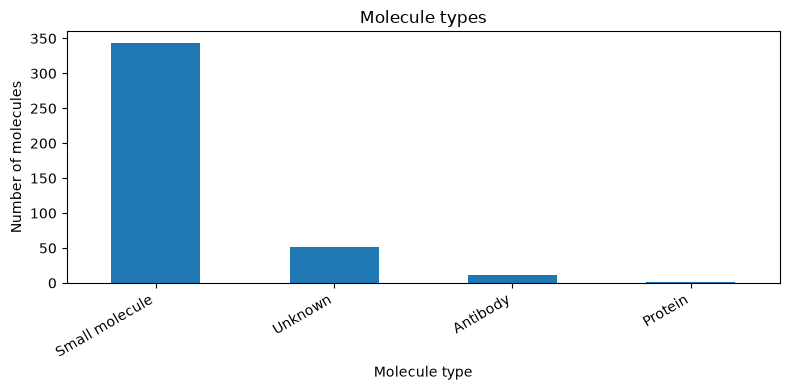

In [4]:
# Distribution of molecule types
display(mol["molecule_type"].value_counts(dropna=False).to_frame("count"))

mol["molecule_type"].value_counts(dropna=False).plot(
    kind="bar", figsize=(8, 4), title="Molecule types"
)
plt.xlabel("Molecule type")
plt.ylabel("Number of molecules")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Output takeaway:** Small molecules dominate the records (343), while 51 are labelled Unknown, 11 Antibody, and 2 Protein. The dataset is therefore not exclusively composed of small molecules, so the project’s molecular-feature workflow should explicitly account for molecule type and structure availability.

,count
max_phase,
1.0,110
2.0,156
3.0,52
4.0,89


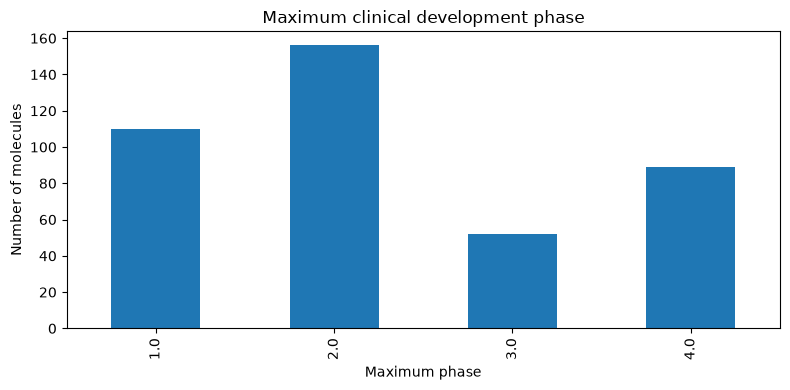

In [5]:
# Clinical development phase distribution
display(mol["max_phase"].value_counts(dropna=False).sort_index().to_frame("count"))

mol["max_phase"].value_counts(dropna=False).sort_index().plot(
    kind="bar", figsize=(8, 4), title="Maximum clinical development phase"
)
plt.xlabel("Maximum phase")
plt.ylabel("Number of molecules")
plt.tight_layout()
plt.show()

**Output takeaway:** The largest development-phase group is Phase 2 (156 molecules), followed by Phase 1 (110), Phase 4 (89), and Phase 3 (52). The dataset spans multiple clinical development stages rather than representing only approved or early-stage compounds.

,count,mean,std,min,25%,50%,75%,max
mol_weight,345.0,503.35,280.29,236.36,412.42,468.48,540.02,3823.50
alogp,343.0,3.83,1.48,-2.87,2.88,3.69,4.88,11.17
hbd,343.0,2.15,1.18,0.00,1.50,2.00,3.00,14.00
hba,343.0,6.76,2.10,1.00,5.00,7.00,8.00,14.00
psa,343.0,97.94,31.17,12.03,80.55,94.14,110.66,355.24
rtb,343.0,5.82,2.60,0.00,4.00,6.00,7.00,22.00
aromatic_rings,343.0,3.38,1.06,0.00,3.00,3.00,4.00,8.00
ro5_violations,343.0,0.58,0.77,0.00,0.00,0.00,1.00,3.00


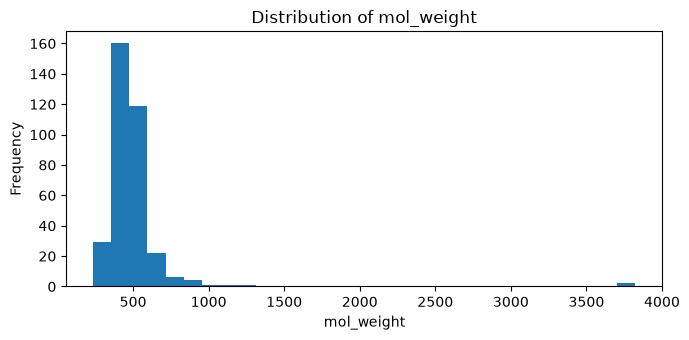

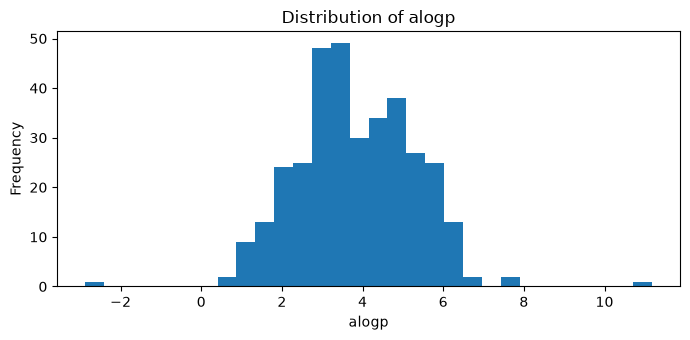

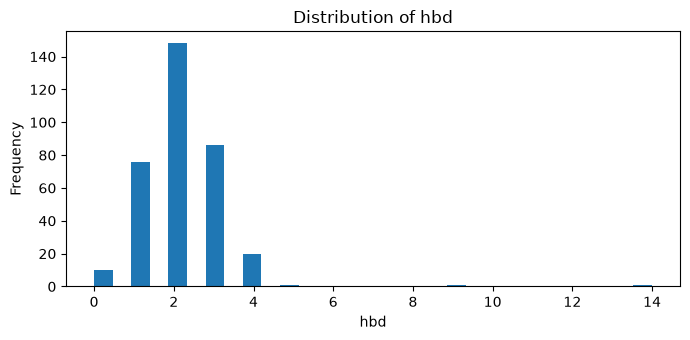

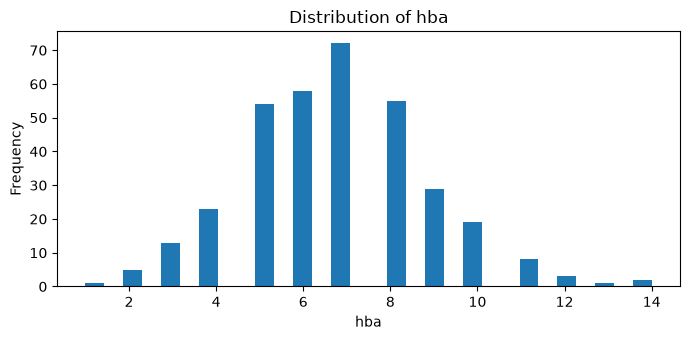

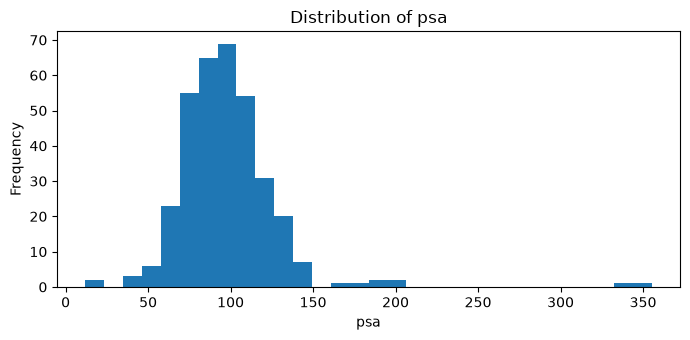

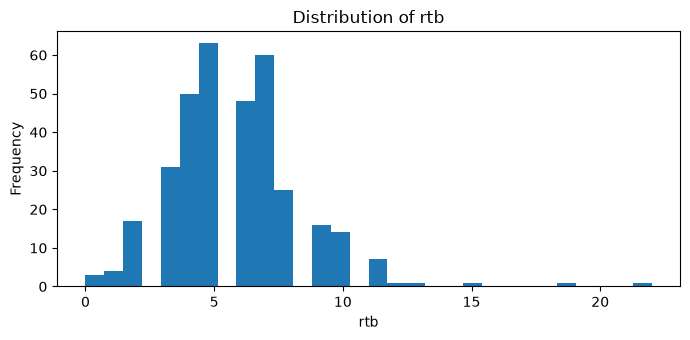

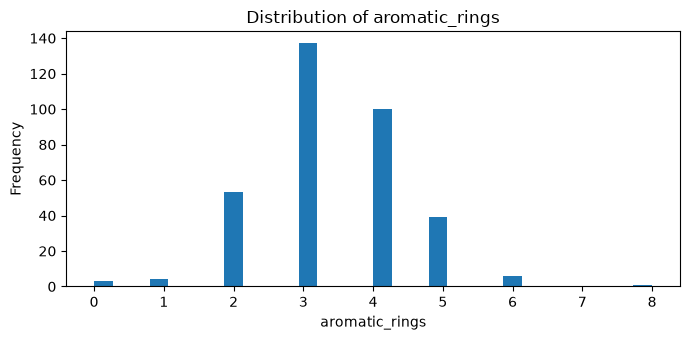

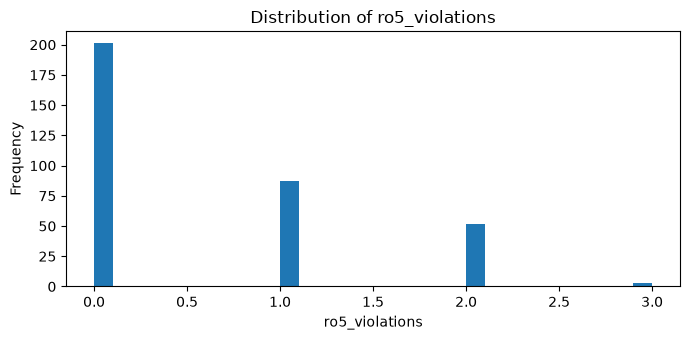

In [6]:
# Physicochemical descriptor distributions
descriptor_cols = [
    "mol_weight", "alogp", "hbd", "hba", "psa", "rtb",
    "aromatic_rings", "ro5_violations"
]
available_descriptors = [c for c in descriptor_cols if c in mol.columns]

display(describe_numeric(mol[available_descriptors]))

for col in available_descriptors:
    values = mol[col].dropna()
    if not values.empty:
        plt.figure(figsize=(7, 3.5))
        plt.hist(values, bins=30)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

**Output takeaway:** Descriptor values show noticeable variation across molecules. The median molecular weight is 468.48, median alogP is 3.69, and median Rule-of-Five violations is 0. Some maximum values are much larger than the central values (for example, molecular weight reaches 3823.50), indicating extreme observations that should be checked before scaling or clustering.

In [7]:
# Repeated structure identifiers
for col in ["inchi_key", "smiles"]:
    if col in mol.columns:
        non_missing = mol[col].dropna()
        duplicated_count = non_missing.duplicated(keep=False).sum()
        print(f"{col}: {duplicated_count} rows belong to repeated non-missing values")
        display(
            mol.loc[mol[col].notna() & mol[col].duplicated(keep=False),
                    ["molecule_chembl_id", "name", col]]
            .sort_values(col)
            .head(20)
        )

inchi_key: 0 rows belong to repeated non-missing values


,molecule_chembl_id,name,inchi_key


smiles: 0 rows belong to repeated non-missing values


,molecule_chembl_id,name,smiles


**Output takeaway:** No repeated non-missing InChIKeys or SMILES were found among the molecule records. This suggests that the available structure identifiers do not reveal exact duplicate structures in this table.

### Molecules — interpretation prompts

- How many molecules have a usable SMILES structure?
- Are all records small molecules, or are other molecule types present?
- Are the descriptor distributions strongly skewed or do they contain extreme values?
- Do repeated SMILES or InChIKeys indicate multiple ChEMBL records for the same structure?
- Which records may need investigation before molecular fingerprint generation?

**Do not decide to remove a molecule in this EDA section.** Record the issue and make a documented decision during preprocessing.

## 2. Activities — experimental potency measurements

Each activity row represents an experimental measurement associated with a molecule, assay, and target. Different measurement types (IC50, Ki, Kd) describe different experimental quantities and should not be treated as directly interchangeable.

In [8]:
# Activity measurement types
for col in ["standard_type", "standard_units"]:
    if col in act.columns:
        display(act[col].value_counts(dropna=False).to_frame("count"))

,count
standard_type,
Kd,9093
IC50,5627
Ki,935


,count
standard_units,
nM,15655


**Output takeaway:** The activity table contains 9,093 Kd records, 5,627 IC50 records, and 935 Ki records. All 15,655 displayed measurements use nM units, so the measurement types are represented in a consistent unit here, although they still describe different experimental endpoints.

,count,mean,median,std,min,max
standard_type,,,,,,
IC50,5627,7.50,7.57,1.18,4.00,10.72
Kd,9093,6.46,6.25,1.00,4.00,10.80
Ki,935,6.93,6.70,1.27,4.21,10.72


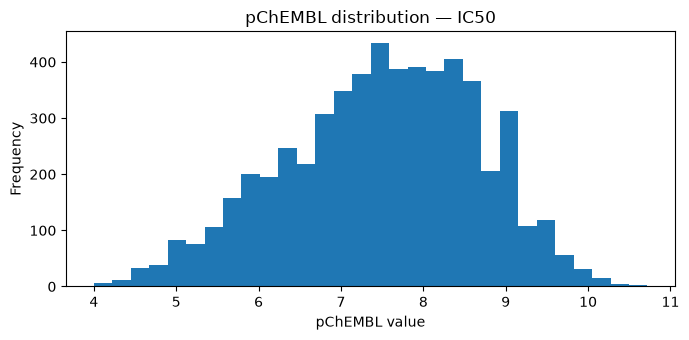

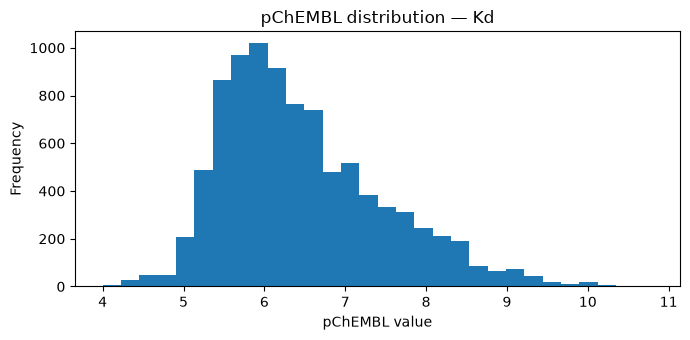

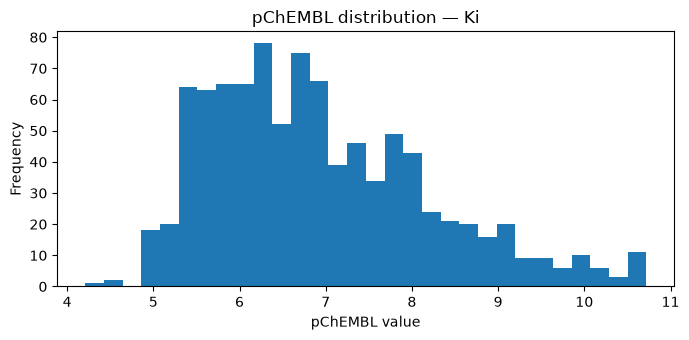

In [9]:
# pChEMBL distributions, separated by measurement type
if {"standard_type", "pchembl_value"}.issubset(act.columns):
    display(
        act.groupby("standard_type")["pchembl_value"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )

    for measurement_type, group in act.groupby("standard_type"):
        values = group["pchembl_value"].dropna()
        if not values.empty:
            plt.figure(figsize=(7, 3.5))
            plt.hist(values, bins=30)
            plt.title(f"pChEMBL distribution — {measurement_type}")
            plt.xlabel("pChEMBL value")
            plt.ylabel("Frequency")
            plt.tight_layout()
            plt.show()

**Output takeaway:** The mean pChEMBL value is highest for IC50 (7.50), followed by Ki (6.93) and Kd (6.46). Their distributions overlap, but the summary statistics indicate differences between measurement types. These endpoints should remain identifiable when interpreting or preparing activity data.

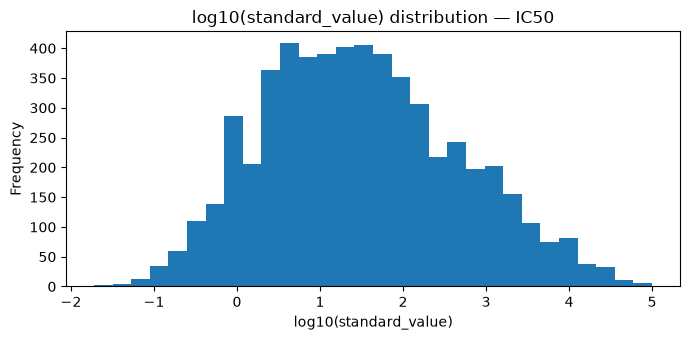

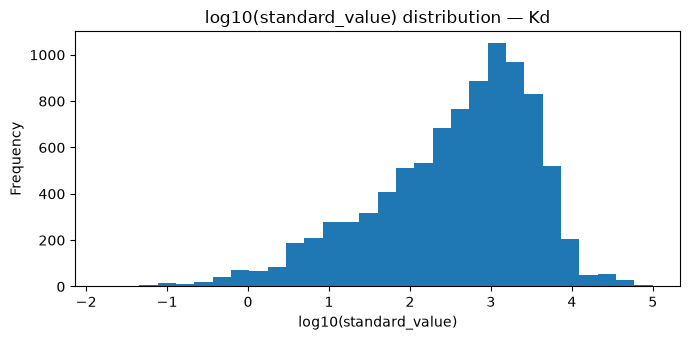

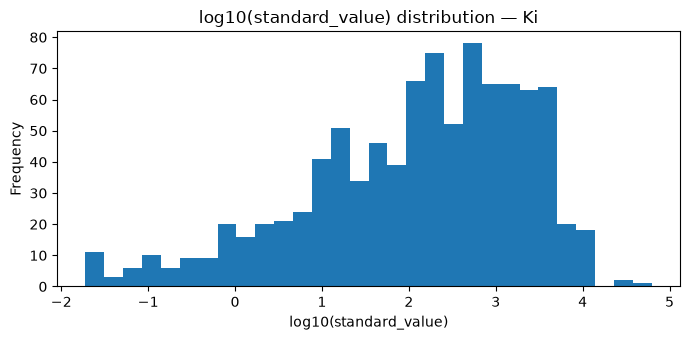

In [10]:
# Standard values by measurement type (inspect on a log scale)
if {"standard_type", "standard_value"}.issubset(act.columns):
    for measurement_type, group in act.groupby("standard_type"):
        values = group["standard_value"].dropna()
        values = values[values > 0]
        if not values.empty:
            plt.figure(figsize=(7, 3.5))
            plt.hist(np.log10(values), bins=30)
            plt.title(f"log10(standard_value) distribution — {measurement_type}")
            plt.xlabel("log10(standard_value)")
            plt.ylabel("Frequency")
            plt.tight_layout()
            plt.show()

**Output takeaway:** The standard-value plots compare IC50, Kd, and Ki measurements on a logarithmic scale. The log scale makes values spanning different orders of magnitude easier to inspect; the plots also reinforce that raw values should be interpreted within their measurement type rather than pooled without care.

In [11]:
# Most frequently measured molecules and targets
if "molecule_chembl_id" in act.columns:
    display(act["molecule_chembl_id"].value_counts().head(15).to_frame("activity_record_count"))

if "target_chembl_id" in act.columns:
    display(act["target_chembl_id"].value_counts().head(15).to_frame("activity_record_count"))

,activity_record_count
molecule_chembl_id,
CHEMBL535,918
CHEMBL603469,722
CHEMBL608533,567
CHEMBL1721885,433
CHEMBL522892,425
CHEMBL1287853,391
CHEMBL428690,380
CHEMBL1873475,362
CHEMBL475251,361


,activity_record_count
target_chembl_id,
CHEMBL1974,726
CHEMBL1862,500
CHEMBL4247,378
CHEMBL5251,344
CHEMBL2971,331
CHEMBL2041,322
CHEMBL2835,226
CHEMBL4005,218
CHEMBL2148,213


**Output takeaway:** Activity records are unevenly distributed across molecules and targets. CHEMBL535 has the most activity records (918), while target CHEMBL1974 has the most target-associated records (726). This imbalance means some molecules and targets are much more extensively measured than others.

In [12]:
# Number of activity records per molecule-target pair
if {"molecule_chembl_id", "target_chembl_id"}.issubset(act.columns):
    pair_counts = (
        act.groupby(["molecule_chembl_id", "target_chembl_id"])
        .size()
        .sort_values(ascending=False)
        .rename("record_count")
    )
    display(pair_counts.head(20).to_frame())

,,record_count
molecule_chembl_id,target_chembl_id,
CHEMBL3916717,CHEMBL5285,204
CHEMBL1873475,CHEMBL5251,138
CHEMBL576982,CHEMBL1974,137
CHEMBL601719,CHEMBL4247,123
CHEMBL2403108,CHEMBL4247,79
CHEMBL1229517,CHEMBL5145,68
CHEMBL535,CHEMBL1974,61
CHEMBL2216870,CHEMBL3130,51
CHEMBL288441,CHEMBL267,49


**Output takeaway:** The number of measurements also varies substantially for molecule–target pairs. The largest pair shown has 204 records, followed by pairs with 138 and 137 records. Repeated measurements may provide richer evidence for some pairs, but can also create an imbalance in the activity data.

### Activities — interpretation prompts

- Which measurement types are present, and how frequent is each?
- Do pChEMBL distributions differ between IC50, Ki, and Kd?
- Are some molecules or targets represented by many more activity records?
- Are there molecule–target pairs with repeated measurements?

**Interpretation caution:** IC50, Ki, and Kd are not interchangeable. Compare values within the same measurement type and, where possible, similar experimental conditions. Activities are biological annotations, not clustering inputs.

## 3. Targets — protein reference information

The `targets` dataset provides the biological identities associated with target identifiers. It is a reference/annotation table rather than a molecular-feature table.

In [13]:
# Identifier and target-name uniqueness
target_checks = pd.DataFrame({
    "metric": ["rows", "unique target IDs", "missing target IDs",
               "unique preferred names", "missing preferred names"],
    "value": [
        len(tgt),
        tgt["target_chembl_id"].nunique(),
        tgt["target_chembl_id"].isna().sum(),
        tgt["pref_name"].nunique(),
        tgt["pref_name"].isna().sum()
    ]
})
display(target_checks)

,metric,value
0,rows,548
1,unique target IDs,548
2,missing target IDs,0
3,unique preferred names,548
4,missing preferred names,0


**Output takeaway:** The targets table contains 548 rows and 548 unique target identifiers, with no missing identifiers or preferred names. The identifiers and preferred names are therefore unique and complete in this reference table.

In [14]:
# Target organism and type
for col in ["organism", "target_type"]:
    if col in tgt.columns:
        display(tgt[col].value_counts(dropna=False).to_frame("count"))

,count
organism,
Homo sapiens,548


,count
target_type,
SINGLE PROTEIN,548


**Output takeaway:** All 548 target records are annotated as *Homo sapiens* and as `SINGLE PROTEIN`. The target reference is consequently consistent in organism and target type for this dataset.

In [15]:
# Inspect target names and name patterns
display(tgt[["target_chembl_id", "pref_name"]].head(20))

if "pref_name" in tgt.columns:
    name_lengths = tgt["pref_name"].dropna().astype(str).str.len()
    display(name_lengths.describe().to_frame("Target-name length"))

,target_chembl_id,pref_name
0,CHEMBL1862,Tyrosine-protein kinase ABL1
1,CHEMBL1824,Receptor tyrosine-protein kinase erbB-2
2,CHEMBL3629,Casein kinase II subunit alpha
3,CHEMBL2159,Nucleoside diphosphate kinase A
4,CHEMBL2160,Nucleoside diphosphate kinase B
5,CHEMBL2468,Death-associated protein kinase 3
6,CHEMBL2469,Uridine-cytidine kinase 2
7,CHEMBL3142,DNA-dependent protein kinase catalytic su...
8,CHEMBL2447,Deoxycytidine kinase
9,CHEMBL3961,Mitogen-activated protein kinase 11


,Target-name length
count,548.000000
mean,39.105839
std,13.335898
min,10.000000
25%,30.000000
50%,36.000000
75%,49.000000
max,78.000000


**Output takeaway:** The sample shows descriptive protein target names, and all 548 preferred names are present. Target-name lengths range from 10 to 78 characters (mean about 39), so names vary in detail but are available for biological interpretation.

### Targets — interpretation prompts

- Are target identifiers unique?
- Are target names duplicated or written in different ways?
- Do organism and target type match the dataset selection criteria?
- Are there target identifiers in `activities` that do not appear in `targets`?

Targets help translate a ChEMBL identifier into a biological entity. They do not provide molecular features for clustering.

## 4. Mechanisms — molecule–target action annotations

Each mechanism record links a molecule to a target and describes its known mechanism or action. This dataset helps interpret the biological context of molecules after clusters have been formed.

,count
action_type,
INHIBITOR,607
NEGATIVE ALLOSTERIC MODULATOR,2
ANTAGONIST,1


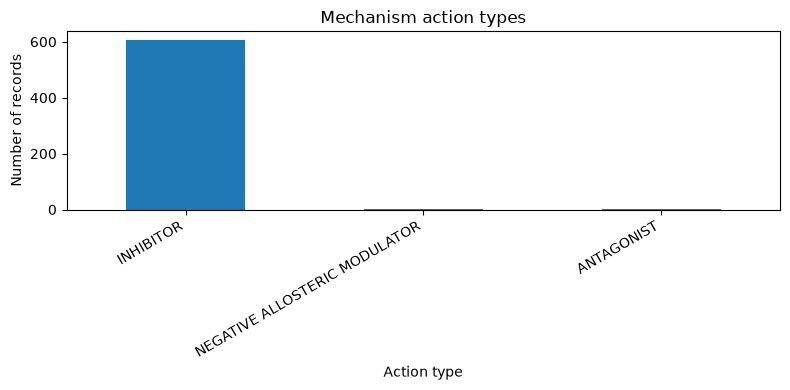

In [16]:
# Action type distribution
display(mech["action_type"].value_counts(dropna=False).to_frame("count"))

mech["action_type"].value_counts(dropna=False).plot(
    kind="bar", figsize=(8, 4), title="Mechanism action types"
)
plt.xlabel("Action type")
plt.ylabel("Number of records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Output takeaway:** Mechanism annotations are overwhelmingly labelled `INHIBITOR` (607 records). Only two records are `NEGATIVE ALLOSTERIC MODULATOR` and one is `ANTAGONIST`. The mechanism data are therefore strongly dominated by inhibitor annotations.

In [17]:
# Most frequent mechanism descriptions
display(mech["mechanism_of_action"].value_counts(dropna=False).head(20).to_frame("count"))

,count
mechanism_of_action,
Tyrosine-protein kinase receptor FLT3 inhibitor,43
MAP kinase p38 alpha inhibitor,35
Receptor protein-tyrosine kinase erbB-2 inhibitor,30
Serine/threonine-protein kinase mTOR inhibitor,26
Tyrosine-protein kinase JAK2 inhibitor,25
Tyrosine-protein kinase BTK inhibitor,22
PI3-kinase p110-delta subunit inhibitor,21
Tyrosine-protein kinase ABL inhibitor,18
Tyrosine-protein kinase JAK1 inhibitor,17


**Output takeaway:** The most frequent mechanism descriptions are mainly kinase-inhibitor annotations, including FLT3, MAP kinase p38 alpha, erbB-2, mTOR, and JAK2. This indicates that kinase-related mechanisms are prominent in the mechanism records shown.

In [18]:
# Number of mechanism records per molecule and per target
for col in ["molecule_chembl_id", "target_chembl_id"]:
    if col in mech.columns:
        display(mech[col].value_counts().head(15).to_frame("mechanism_record_count"))

,mechanism_record_count
molecule_chembl_id,
CHEMBL3109738,7
CHEMBL1946170,6
CHEMBL495727,6
CHEMBL428690,6
CHEMBL1944698,6
CHEMBL3545083,6
CHEMBL574737,5
CHEMBL14762,5
CHEMBL290352,5


,mechanism_record_count
target_chembl_id,
CHEMBL1974,43
CHEMBL260,35
CHEMBL1824,31
CHEMBL2842,26
CHEMBL2971,25
CHEMBL5251,22
CHEMBL3130,21
CHEMBL1862,18
CHEMBL2835,17


**Output takeaway:** Mechanism annotations are not evenly distributed. One molecule has seven mechanism records, and the most frequently represented target has 43. This suggests that some molecules and targets have broader mechanism annotation coverage than others.

In [19]:
# Molecules associated with more than one action type
if {"molecule_chembl_id", "action_type"}.issubset(mech.columns):
    action_types_per_molecule = (
        mech.groupby("molecule_chembl_id")["action_type"]
        .nunique()
        .sort_values(ascending=False)
    )
    display(action_types_per_molecule[action_types_per_molecule > 1].to_frame(
        "number_of_action_types"
    ))

,number_of_action_types
molecule_chembl_id,
CHEMBL3545071,2


**Output takeaway:** Only one molecule in the displayed result, CHEMBL3545071, is associated with more than one action type. Most molecules therefore appear to have a single recorded action type in this dataset.

### Mechanisms — interpretation prompts

- Which action types are present?
- Are inhibitor records the majority?
- Do some molecules have several mechanism records or action types?
- Are mechanism descriptions repeated across multiple molecules?

Do not automatically delete non-`INHIBITOR` records during EDA. Inspect them and document any later analytical filtering. Mechanism annotations are not clustering inputs.

## 5. Indications — molecule–disease annotations

The `indications` dataset links molecules to diseases or conditions. It is used to explore the therapeutic context represented in the dataset, not to define the molecular clusters.

In [20]:
# Most frequent EFO and MeSH disease terms
for col in ["efo_term", "mesh_heading"]:
    if col in ind.columns:
        display(ind[col].value_counts(dropna=False).head(20).to_frame("indication_record_count"))

,indication_record_count
efo_term,
neoplasm,178
cancer,104
non-small cell lung carcinoma,97
breast cancer,82
acute myeloid leukemia,55
lymphoma,48
pancreatic carcinoma,46
prostate cancer,41
multiple myeloma,39


,indication_record_count
mesh_heading,
Neoplasms,283
Breast Neoplasms,144
"Carcinoma, Non-Small-Cell Lung",97
Melanoma,72
Colorectal Neoplasms,64
"Leukemia, Myeloid, Acute",57
Pancreatic Neoplasms,55
Ovarian Neoplasms,53
Lymphoma,48


**Output takeaway:** The most frequent EFO terms include neoplasm (178), cancer (104), and non-small cell lung carcinoma (97). The MeSH results show a similar emphasis on neoplasms and cancer-related conditions. Disease annotations are concentrated in several recurring therapeutic areas, especially oncology.

,count
max_phase_for_ind,
0.5,21
1.0,997
2.0,1324
3.0,260
4.0,262


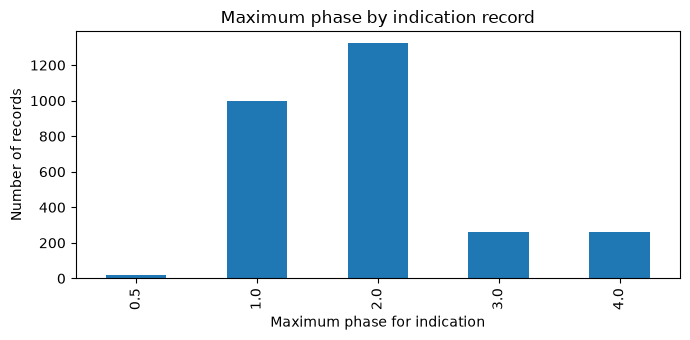

In [21]:
# Clinical phase associated with each molecule-indication record
if "max_phase_for_ind" in ind.columns:
    display(ind["max_phase_for_ind"].value_counts(dropna=False).sort_index().to_frame("count"))

    ind["max_phase_for_ind"].value_counts(dropna=False).sort_index().plot(
        kind="bar", figsize=(7, 3.5), title="Maximum phase by indication record"
    )
    plt.xlabel("Maximum phase for indication")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

**Output takeaway:** Most indication records are associated with Phase 2 (1,324) or Phase 1 (997). Phase 3 and Phase 4 each account for 260 and 262 records respectively, while 21 records are at Phase 0.5. Indication annotations therefore cover several clinical development stages, with Phase 1 and 2 most represented.

In [22]:
# Number of indications per molecule
if "molecule_chembl_id" in ind.columns:
    indications_per_molecule = (
        ind.groupby("molecule_chembl_id")
        .size()
        .sort_values(ascending=False)
        .rename("indication_count")
    )
    display(indications_per_molecule.head(20).to_frame())
    display(indications_per_molecule.describe().to_frame("Indications per molecule"))

,indication_count
molecule_chembl_id,
CHEMBL1421,88
CHEMBL1201585,85
CHEMBL1642,82
CHEMBL1200485,70
CHEMBL535,66
CHEMBL1567,64
CHEMBL3301610,53
CHEMBL24828,53
CHEMBL1873475,49


,Indications per molecule
count,359.000000
mean,7.977716
std,12.330167
min,1.000000
25%,1.000000
50%,4.000000
75%,8.000000
max,88.000000


**Output takeaway:** The number of indications per molecule is highly variable: the median is 4, the mean is about 8, and the maximum is 88. The distribution is therefore skewed, with a small number of molecules linked to many indications and many molecules linked to relatively few.

In [23]:
# Inspect EFO–MeSH term pairs
if {"efo_term", "mesh_heading"}.issubset(ind.columns):
    disease_pairs = (
        ind.groupby(["efo_term", "mesh_heading"])
        .size()
        .sort_values(ascending=False)
        .rename("record_count")
    )
    display(disease_pairs.head(25).to_frame())

,,record_count
efo_term,mesh_heading,
neoplasm,Neoplasms,178
cancer,Neoplasms,104
non-small cell lung carcinoma,"Carcinoma, Non-Small-Cell Lung",97
breast cancer,Breast Neoplasms,82
acute myeloid leukemia,"Leukemia, Myeloid, Acute",55
lymphoma,Lymphoma,48
pancreatic carcinoma,Pancreatic Neoplasms,46
prostate cancer,"Prostatic Neoplasms, Castration-Resistant",41
multiple myeloma,Multiple Myeloma,39


**Output takeaway:** The most frequent EFO–MeSH pairs connect corresponding disease concepts, such as non-small cell lung carcinoma with its MeSH term and breast cancer with Breast Neoplasms. This suggests that the two annotation vocabularies often describe related disease concepts, while retaining different naming conventions.

### Indications — interpretation prompts

- Which disease terms occur most frequently?
- How many indications are associated with each molecule?
- What clinical phases are represented?
- Do EFO and MeSH use different labels for related disease concepts?

EFO and MeSH are separate controlled vocabularies, so their terms may not match word-for-word. Do not assume two differently named terms are identical without checking their definitions.

## 6. Cross-dataset relationship checks

This section checks whether the ChEMBL identifiers connect the five datasets as expected. These joins are for data understanding and annotation coverage only; they do not turn the annotation tables into clustering inputs.

In [24]:
# Molecule-ID coverage across annotation datasets
molecule_ids = set(mol["molecule_chembl_id"].dropna())

coverage_rows = []
for name, df in {
    "activities": act,
    "mechanisms": mech,
    "indications": ind
}.items():
    ids = set(df["molecule_chembl_id"].dropna())
    coverage_rows.append({
        "dataset": name,
        "unique_molecule_ids": len(ids),
        "ids_found_in_molecules": len(ids & molecule_ids),
        "ids_not_found_in_molecules": len(ids - molecule_ids)
    })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

,dataset,unique_molecule_ids,ids_found_in_molecules,ids_not_found_in_molecules
0,activities,262,262,0
1,mechanisms,407,407,0
2,indications,359,359,0


**Output takeaway:** Every unique molecule identifier found in the annotation tables is present in the molecules table: 262/262 for activities, 407/407 for mechanisms, and 359/359 for indications. No unmatched molecule identifiers were found in these three datasets.

In [25]:
# Activity target-ID coverage against the targets reference table
if "target_chembl_id" in act.columns and "target_chembl_id" in tgt.columns:
    activity_target_ids = set(act["target_chembl_id"].dropna())
    reference_target_ids = set(tgt["target_chembl_id"].dropna())

    print("Unique target IDs in activities:", len(activity_target_ids))
    print("Activity target IDs found in targets:", len(activity_target_ids & reference_target_ids))
    print("Activity target IDs missing from targets:", len(activity_target_ids - reference_target_ids))

    missing_target_ids = sorted(activity_target_ids - reference_target_ids)
    print("Examples of unmatched target IDs:", missing_target_ids[:20])

Unique target IDs in activities: 381
Activity target IDs found in targets: 381
Activity target IDs missing from targets: 0
Examples of unmatched target IDs: []


**Output takeaway:** All 381 unique target identifiers used in activity records are present in the targets reference table. There are no unmatched activity target IDs, so the activity-to-target identifier relationship is complete for the records checked.

In [26]:
# Annotation coverage per molecule (counts only; no raw data modification)
annotation_counts = pd.DataFrame({
    "molecule_chembl_id": mol["molecule_chembl_id"]
})

for name, df in {
    "activity_records": act,
    "mechanism_records": mech,
    "indication_records": ind
}.items():
    counts = df.groupby("molecule_chembl_id").size()
    annotation_counts[name] = annotation_counts["molecule_chembl_id"].map(counts).fillna(0).astype(int)

display(annotation_counts.head())
display(annotation_counts[["activity_records", "mechanism_records", "indication_records"]].describe().T)

,molecule_chembl_id,activity_records,mechanism_records,indication_records
0,CHEMBL9960,0,1,3
1,CHEMBL288441,360,4,20
2,CHEMBL103667,221,1,2
3,CHEMBL1421,76,1,88
4,CHEMBL1642,2,1,82


,count,mean,std,min,25%,50%,75%,max
activity_records,407.0,38.464373,93.397994,0.0,0.0,6.0,29.0,918.0
mechanism_records,407.0,1.498771,0.959461,1.0,1.0,1.0,2.0,7.0
indication_records,407.0,7.036855,11.861521,0.0,1.0,3.0,8.0,88.0


**Output takeaway:** Annotation coverage varies by molecule. Activity counts range from 0 to 918 (median 6), mechanism counts from 1 to 7 (median 1), and indication counts from 0 to 88 (median 3). This uneven coverage should be kept in mind when combining annotations or comparing molecules.

## 7. Phase 4 conclusions and handoff to preprocessing

### EDA summary

- **Molecules:** The dataset contains 407 molecules. SMILES are available for 345 (84.77%), while 62 are missing. Small molecules are the largest group (343), but other and unknown molecule types are also present. No duplicate non-missing SMILES or InChIKeys were detected. Physicochemical descriptors vary widely, with some extreme values that should be reviewed before preprocessing.
- **Activities:** There are 15,655 measurements, mainly Kd (9,093) and IC50 (5,627), with fewer Ki records (935). All reported units are nM. pChEMBL distributions differ by measurement type, and activity counts are highly imbalanced across molecules, targets, and molecule–target pairs.
- **Targets:** The reference table contains 548 unique, fully named targets. All are annotated as *Homo sapiens* and `SINGLE PROTEIN`.
- **Mechanisms:** The 610 mechanism records are dominated by inhibitor annotations (607). Mechanism coverage varies across molecules and targets, although most molecules in the result have one recorded action type.
- **Indications:** The 2,864 indication records are concentrated in cancer-related terms. Most indication records are associated with Phase 1 or Phase 2, and the number of indications per molecule is uneven.
- **Cross-dataset links:** All molecule identifiers checked in activities, mechanisms, and indications match the molecule table. All 381 activity target identifiers also match the targets reference table.

### Overall conclusion

The datasets have strong identifier coverage, but their annotation counts and molecular descriptors are unevenly distributed. Missing SMILES, non-small-molecule records, extreme descriptor values, and differences between activity measurement types should be considered during preprocessing. For molecular clustering, the next phase should prioritize valid molecular structures and molecular features; activity, target, mechanism, and indication data can support interpretation rather than replace molecular information.